<a href="https://colab.research.google.com/github/hereisamara/ml-basics/blob/main/RNN_LSTM_HandsOn_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Recurrent Neural Networks (RNNs) and LSTM — Hands-on Notebook

This notebook teaches RNNs/LSTMs step by step with runnable PyTorch code.

We will learn sequence data, hidden states, vanishing gradients, LSTM gates, training, evaluation, and experiments.

## 1. Setup

We use PyTorch, NumPy, and Matplotlib. The notebook automatically uses GPU if available.

In [1]:
import math, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

Using device: cpu


## 2. What is sequence data?

Sequence data has order. Examples: text, stock prices, audio, ECG, sensor logs.

An RNN processes one step at a time and keeps memory called the **hidden state**:

$$h_t = f(x_t, h_{t-1})$$

So the model uses both the current input and what it remembers from previous steps.

![](https://aiml.com/wp-content/uploads/2023/09/example-of-sequential-data-1.png)

## 3. Create a toy time-series dataset

Task: given previous `seq_len` values, predict the next value.

Input: `[x1, x2, ..., x30]` → Target: `x31`.

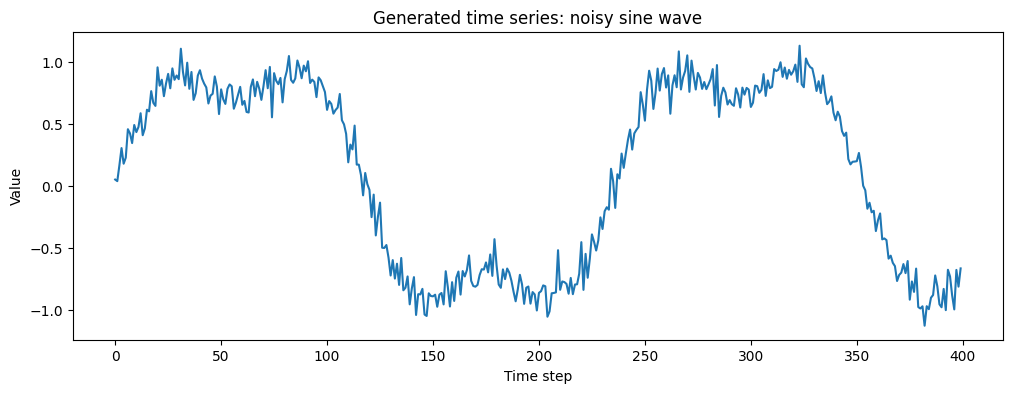

In [2]:
def generate_series(n_points=3000):
    x = np.linspace(0, 80, n_points)
    y = np.sin(x) + 0.3 * np.sin(3 * x) + 0.1 * np.random.randn(n_points)
    return y.astype(np.float32)

series = generate_series()
plt.figure(figsize=(12, 4))
plt.plot(series[:400])
plt.title("Generated time series: noisy sine wave")
plt.xlabel("Time step"); plt.ylabel("Value")
plt.show()

## 4. Convert the series into supervised samples

For each sample:

- `x` shape = `[seq_len, 1]`
- `y` shape = `[1]`

The `1` means each time step has one feature.

In [3]:
class TimeSeriesDataset(Dataset):
    def __init__(self, series, seq_len=30):
        self.series = torch.tensor(series, dtype=torch.float32)
        self.seq_len = seq_len

    def __len__(self):
        return len(self.series) - self.seq_len

    def __getitem__(self, idx):
        x = self.series[idx:idx+self.seq_len].unsqueeze(-1)
        y = self.series[idx+self.seq_len].unsqueeze(-1)
        return x, y

seq_len = 30
train_size = int(len(series) * 0.8)
train_series = series[:train_size]
test_series = series[train_size - seq_len:]

train_dataset = TimeSeriesDataset(train_series, seq_len)
test_dataset = TimeSeriesDataset(test_series, seq_len)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

x_batch, y_batch = next(iter(train_loader))
print("x_batch:", x_batch.shape)
print("y_batch:", y_batch.shape)

x_batch: torch.Size([64, 30, 1])
y_batch: torch.Size([64, 1])


## 5. Vanilla RNN model

A vanilla RNN updates memory as:

$$h_t = tanh(W_xx_t + W_hh_{t-1} + b)$$

For prediction, we take the last hidden output because it summarizes the sequence.

** here, “Vanilla” just means basic / standard / no modifications.

```Previous memory              Current input
   h(t-1)                         x(t)
      │                            │
      │                            │
      ▼                            ▼
  multiply by Wh              multiply by Wx
      │                            │
      └──────────────┬─────────────┘
                     ▼
              add bias b
                     │
                     ▼
              tanh activation
                     │
                     ▼
              new memory h(t)
```


```
Sentence: "I love deep learning"

Step 1:
x1 = "I"
h0 = initial memory, usually zeros
h1 = tanh(Wx*x1 + Wh*h0 + b)

Step 2:
x2 = "love"
h1 = memory from "I"
h2 = tanh(Wx*x2 + Wh*h1 + b)

Step 3:
x3 = "deep"
h2 = memory from "I love"
h3 = tanh(Wx*x3 + Wh*h2 + b)

Step 4:
x4 = "learning"
h3 = memory from "I love deep"
h4 = tanh(Wx*x4 + Wh*h3 + b)
```

![](https://www.researchgate.net/profile/Anwar-Khan-12/publication/373505006/figure/fig2/AS:11431281184601307@1693401433066/The-basic-architecture-of-the-recurrent-neural-networks-RNNs.png)

In [4]:
class SimpleRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1):
        '''
        input_size: number of features at each time step
        → e.g. 1 for time-series, or embedding size for text
        hidden_size: size of hidden state h_t
        → memory capacity of RNN
        num_layers: how many stacked RNN layers
        '''

        super().__init__()
        self.rnn = nn.RNN(input_size,
                          hidden_size,
                          num_layers,
                          batch_first=True,
                          nonlinearity="tanh" # activation func
                          ) # rnn model object loaded from nn modules
        self.fc = nn.Linear(hidden_size, 1) # fully connected layer, output head, 1 binary output or regression output

    def forward(self, x):
        out, h_n = self.rnn(x)
        last_out = out[:, -1, :]
        return self.fc(last_out)

rnn_model = SimpleRNN().to(DEVICE)
print(rnn_model)

SimpleRNN(
  (rnn): RNN(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


## 6. LSTM model

Vanilla RNNs can forget long-term information because gradients may become very small across many time steps. This is the **vanishing gradient problem**.

LSTM improves memory using gates:

- **Forget gate**: what to remove
- **Input gate**: what to store
- **Cell state**: long-term memory
- **Output gate**: what to reveal

Simple idea: RNN has simple memory; LSTM has controlled memory.

![](https://ashutoshtripathi.com/wp-content/uploads/2021/06/rnn-vs-lstm.png)

In [5]:
class SimpleLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        last_out = out[:, -1, :]
        return self.fc(last_out)

lstm_model = SimpleLSTM().to(DEVICE)
print(lstm_model)

SimpleLSTM(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


## 7. Training function

Training loop:

1. Forward pass
2. Compute MSE loss
3. Clear old gradients
4. Backpropagation
5. Update weights

In [6]:
def train_model(model, train_loader, epochs=10, lr=0.001):
    criterion = nn.MSELoss() # loss func # Mean Squared Error
    optimizer = torch.optim.Adam(model.parameters(), lr=lr) # optmizer # adaptive gradient optimizer
    losses = []
    model.train() # Set training mode like self.training = True

    for epoch in range(1, epochs + 1):
        total_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x)
            loss = criterion(pred, y)

            optimizer.zero_grad() # Clear old gradients
            loss.backward() # Backpropagation
            optimizer.step() # Update weights

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        losses.append(avg_loss)
        print(f"Epoch {epoch:02d} | Loss: {avg_loss:.6f}")
    return losses

## 8. Train RNN and LSTM

Run both cells and compare the losses.

In [7]:
rnn_model = SimpleRNN(hidden_size=32).to(DEVICE)
rnn_losses = train_model(rnn_model, train_loader, epochs=10, lr=0.001)

Epoch 01 | Loss: 0.242135
Epoch 02 | Loss: 0.027551
Epoch 03 | Loss: 0.017214
Epoch 04 | Loss: 0.014744
Epoch 05 | Loss: 0.014081
Epoch 06 | Loss: 0.014624
Epoch 07 | Loss: 0.014101
Epoch 08 | Loss: 0.013728
Epoch 09 | Loss: 0.013811
Epoch 10 | Loss: 0.014374


In [8]:
lstm_model = SimpleLSTM(hidden_size=32).to(DEVICE)
lstm_losses = train_model(lstm_model, train_loader, epochs=10, lr=0.001)

Epoch 01 | Loss: 0.417331
Epoch 02 | Loss: 0.091042
Epoch 03 | Loss: 0.035564
Epoch 04 | Loss: 0.023209
Epoch 05 | Loss: 0.018824
Epoch 06 | Loss: 0.014883
Epoch 07 | Loss: 0.013384
Epoch 08 | Loss: 0.012935
Epoch 09 | Loss: 0.013095
Epoch 10 | Loss: 0.012685


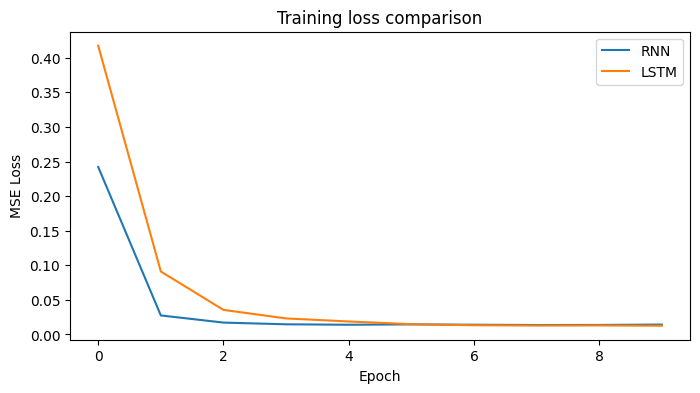

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(rnn_losses, label="RNN")
plt.plot(lstm_losses, label="LSTM")
plt.title("Training loss comparison")
plt.xlabel("Epoch"); plt.ylabel("MSE Loss")
plt.legend(); plt.show()

## 9. Evaluate predictions

A good model should follow the wave pattern on unseen test data.

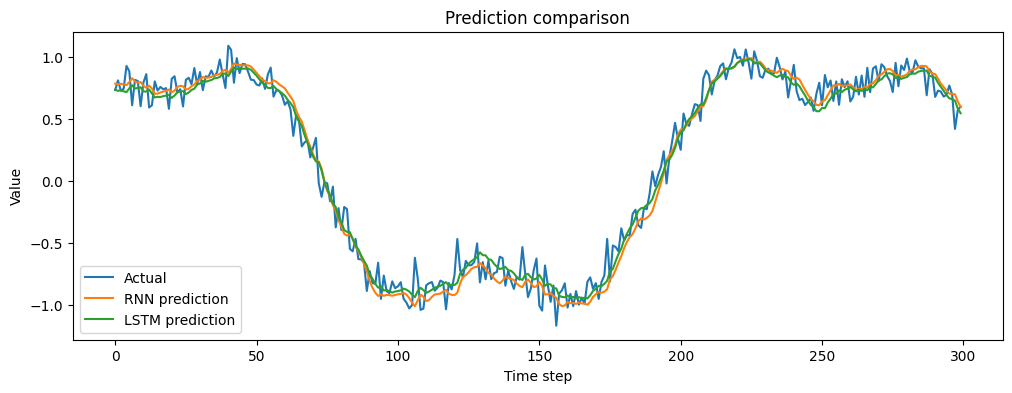

In [10]:
def get_predictions(model, loader):
    model.eval()
    preds, actuals = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            pred = model(x).cpu().numpy()
            preds.extend(pred.flatten())
            actuals.extend(y.numpy().flatten())
    return np.array(preds), np.array(actuals)

rnn_preds, actuals = get_predictions(rnn_model, test_loader)
lstm_preds, _ = get_predictions(lstm_model, test_loader)

plt.figure(figsize=(12, 4))
plt.plot(actuals[:300], label="Actual")
plt.plot(rnn_preds[:300], label="RNN prediction")
plt.plot(lstm_preds[:300], label="LSTM prediction")
plt.title("Prediction comparison")
plt.xlabel("Time step"); plt.ylabel("Value")
plt.legend(); plt.show()

## 10. Manual RNN hidden-state intuition

This shows how an RNN updates hidden memory step by step. This is only forward logic, not training.

In [11]:
torch.manual_seed(0)
input_size = 1
hidden_size = 3
Wx = torch.randn(input_size, hidden_size)
Wh = torch.randn(hidden_size, hidden_size)
b = torch.zeros(hidden_size)

sequence = torch.tensor([[0.1], [0.2], [0.3], [0.4]])
h = torch.zeros(hidden_size)
print("Initial hidden state:", h)
for t, x_t in enumerate(sequence, start=1):
    h = torch.tanh(x_t @ Wx + h @ Wh + b)
    print(f"Step {t}, input={x_t.item():.1f}, hidden={h}")

Initial hidden state: tensor([0., 0., 0.])
Step 1, input=0.1, hidden=tensor([ 0.1529, -0.0293, -0.2145])
Step 2, input=0.2, hidden=tensor([ 0.4380, -0.1205, -0.5834])
Step 3, input=0.3, hidden=tensor([ 0.7153, -0.3059, -0.8580])
Step 4, input=0.4, hidden=tensor([ 0.8471, -0.5632, -0.9476])


## 11. Practice experiments

Try these changes:

1. Change `hidden_size` from 32 to 8, 64, 128
2. Change `seq_len` from 30 to 80
3. Increase noise in `generate_series()`
4. Add `num_layers=2`
5. Replace `nn.LSTM` with `nn.GRU`

Main learning question: when the sequence becomes longer or noisier, which model is more stable?

## 12. Final summary

RNN and LSTM are for sequence learning.

```text
Sequence comes step by step.
The model updates memory.
The final memory is used for prediction.
```

RNN: simple memory, faster, but weaker for long dependencies.

LSTM: gated memory, better for longer dependencies, but more parameters.

Mental model:

```text
RNN asks: What should I remember now?
LSTM asks: What should I forget, store, and output?
```